ACTION REQUIRED: Click 'Choose Files' below and upload:
 -> 'sign_mnist_train.csv' AND 'sign_mnist_test.csv'
    OR the downloaded 'sign-language-mnist.zip' file


Saving sign_mnist_test.csv to sign_mnist_test (1).csv
Saving sign_mnist_train.csv to sign_mnist_train (1).csv

[✓] Dataset files verified successfully!
Training samples: 27455 | Testing samples: 7172

Plotting PCA 2D Feature Cluster Map...


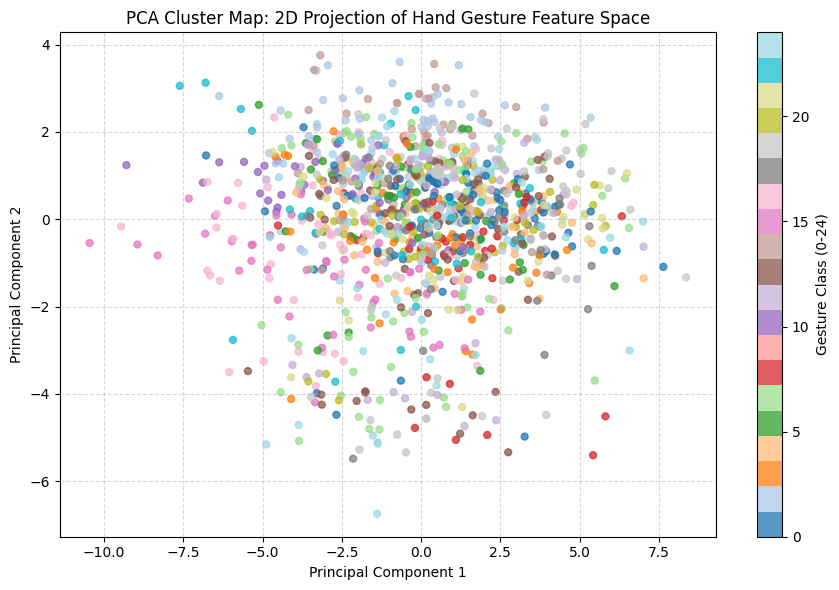

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,098 (887.10 KB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)


Training CNN for 5 epochs (takes ~20 seconds on GPU)...
Epoch 1/5
344/344 ━━━━━━━━━━━━━━━━━━━━ 21s 56ms/step - accuracy: 0.4539 - loss: 1.7977 - val_accuracy: 0.8436 - val_loss: 0.5654
Epoch 2/5
344/344 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.8249 - loss: 0.5371 - val_accuracy: 0.9603 - val_loss: 0.1836
Epoch 3/5
344/344 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.9155 - loss: 0.2655 - val_accuracy: 0.9922 - val_loss: 0.0624
Epoch 4/5
344/344 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.9557 - loss: 0.1481 - val_accuracy: 0.9987 - val_loss: 0.0224
Epoch 5/5
344/344 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.9717 - loss: 0.0970 - val_accuracy: 0.9996 - val_loss: 0.0104


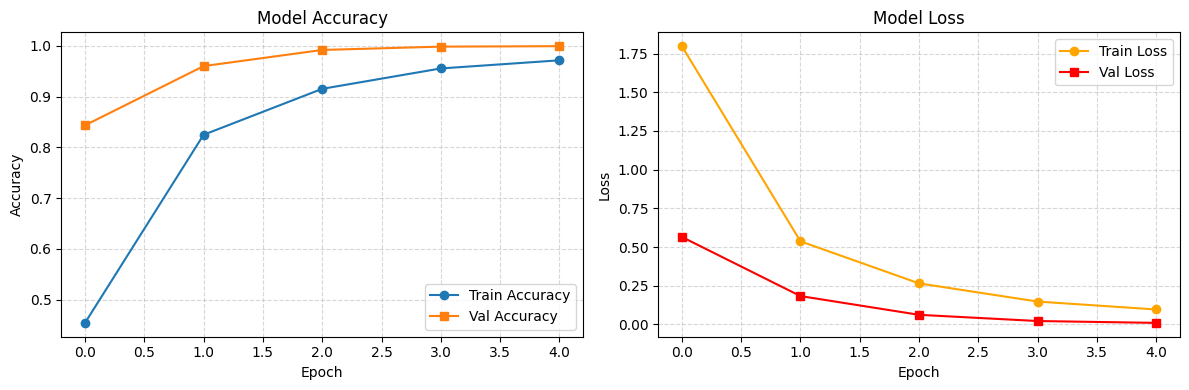


Final Test Accuracy: 90.56%



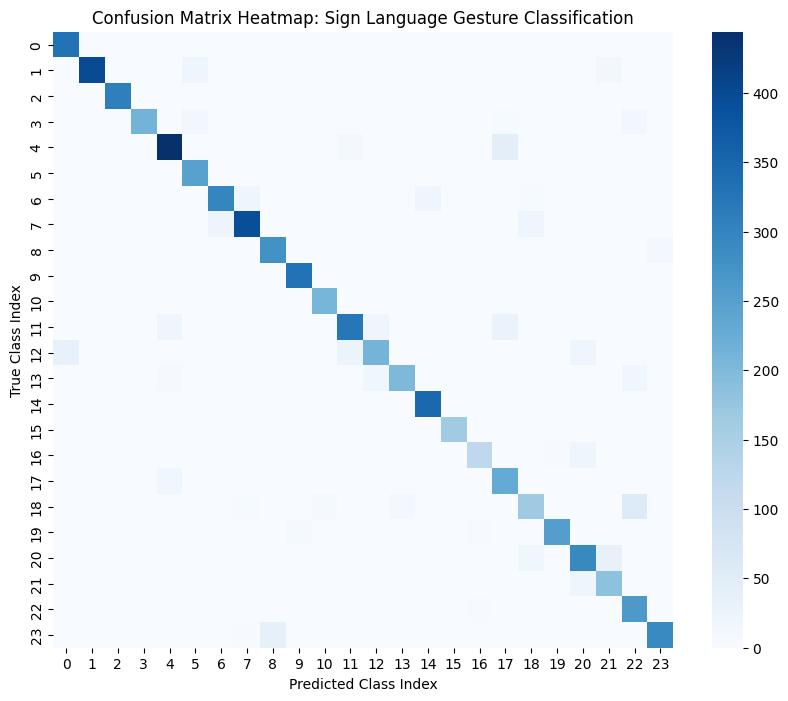

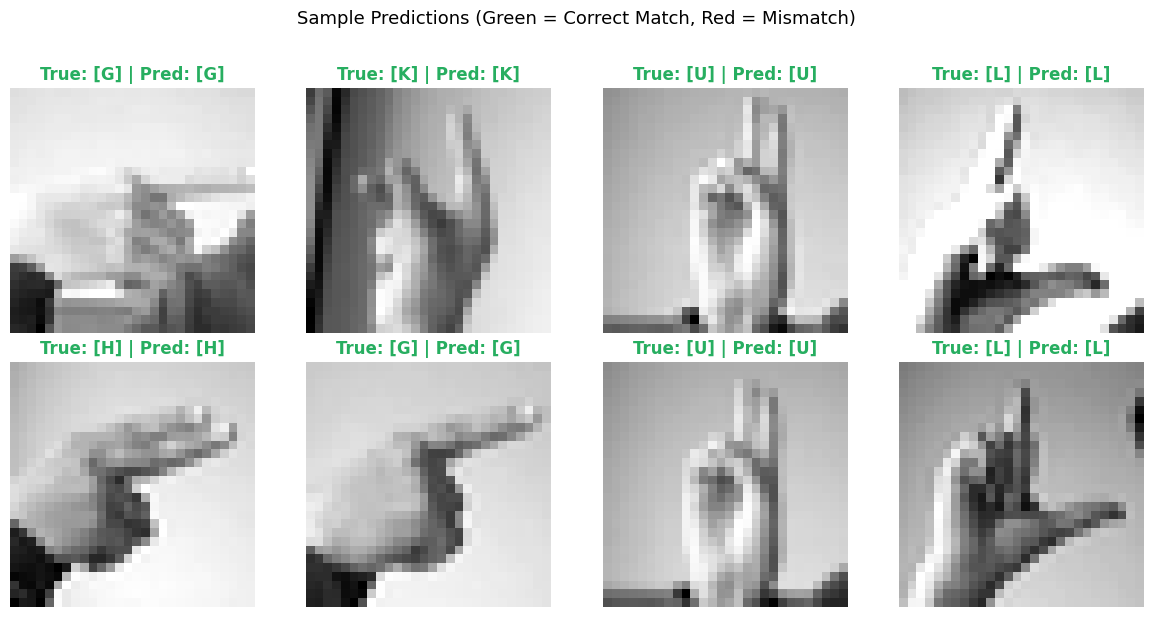

In [ ]:


import os
import zipfile
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from google.colab import files



print("ACTION REQUIRED: Click 'Choose Files' below and upload:")
print(" -> 'sign_mnist_train.csv' AND 'sign_mnist_test.csv'")
print("    OR the downloaded 'sign-language-mnist.zip' file")


uploaded = files.upload()

# Check if a zip file was uploaded and extract it automatically
for filename in uploaded.keys():
    if filename.endswith(".zip"):
        print(f"\nUnpacking {filename}...")
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall(".")

# Verify files are present
if not (os.path.exists("sign_mnist_train.csv") and os.path.exists("sign_mnist_test.csv")):
    raise FileNotFoundError(
        "Could not find 'sign_mnist_train.csv' and 'sign_mnist_test.csv'. "
        "Please ensure both CSV files or the zip file were uploaded."
    )

print("\n[✓] Dataset files verified successfully!")


train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

print(f"Training samples: {train_df.shape[0]} | Testing samples: {test_df.shape[0]}")

# Separate pixel values (X) and label (y), and normalize [0, 255] -> [0, 1]
X_train = train_df.drop("label", axis=1).values / 255.0
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values / 255.0
y_test = test_df["label"].values

# Reshape 784 flat pixels into 28x28x1 image matrices for the CNN
X_train_img = X_train.reshape(-1, 28, 28, 1)
X_test_img = X_test.reshape(-1, 28, 28, 1)

# Mapping dictionary: integer index (0-24) to English alphabet (A-Y)
alphabet = list(string.ascii_uppercase)
label_map = {i: alphabet[i] for i in range(25)}


print("\nPlotting PCA 2D Feature Cluster Map...")
pca = PCA(n_components=2)
subset_X = X_train[:1200]
subset_y = y_train[:1200]
X_pca = pca.fit_transform(subset_X)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=subset_y, cmap="tab20", s=25, alpha=0.75)
plt.colorbar(scatter, label="Gesture Class (0-24)")
plt.title("PCA Cluster Map: 2D Projection of Hand Gesture Feature Space", fontsize=12)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


model = Sequential([
    # First Conv Block
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    # Second Conv Block
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Classifier Head
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(26, activation="softmax")  # 26 possible alphabet slots
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

print("\nTraining CNN for 5 epochs (takes ~20 seconds on GPU)...")
history = model.fit(
    X_train_img,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history["accuracy"], label="Train Accuracy", marker="o")
ax1.plot(history.history["val_accuracy"], label="Val Accuracy", marker="s")
ax1.set_title("Model Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(history.history["loss"], label="Train Loss", marker="o", color="orange")
ax2.plot(history.history["val_loss"], label="Val Loss", marker="s", color="red")
ax2.set_title("Model Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Evaluate on unseen test set
test_loss, test_acc = model.evaluate(X_test_img, y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%\n")

# Confusion Matrix Heatmap
y_pred = np.argmax(model.predict(X_test_img, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, cmap="Blues", annot=False)
plt.title("Confusion Matrix Heatmap: Sign Language Gesture Classification", fontsize=12)
plt.xlabel("Predicted Class Index")
plt.ylabel("True Class Index")
plt.show()


plt.figure(figsize=(12, 6))
for i in range(8):
    idx = np.random.randint(0, len(X_test_img))
    actual_letter = label_map[y_test[idx]]
    predicted_letter = label_map[y_pred[idx]]

    # Green title if correct, Red title if incorrect
    is_correct = (actual_letter == predicted_letter)
    text_color = "#27ae60" if is_correct else "#c0392b"

    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test_img[idx].reshape(28, 28), cmap="gray")
    plt.title(f"True: [{actual_letter}] | Pred: [{predicted_letter}]", color=text_color, fontweight="bold")
    plt.axis("off")

plt.suptitle("Sample Predictions (Green = Correct Match, Red = Mismatch)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()